# ZTF (DAOPhot reference catalogs) vs Pan-STARRS, quadrant 643_11_1

Inputs come from the merge and match run on 2026-11-11: three ZTF `refpsfcat` catalogs merged into objects (mutual nearest neighbour at 1"), then matched to PS1 objects the same way. Tables live in `Data/ztf_data/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

obj = pd.read_parquet('../Data/ztf_data/ztfobj_643_11_1.parquet')   # one row per ZTF object; {band}_mag etc.; ps1_idx, ps1_sep
ps1 = pd.read_parquet('../Data/ztf_data/ps1_643_11_1.parquet')      # PS1 objects on valid ZTF pixels; ps1_idx indexes this
matched = obj[obj.ps1_idx >= 0].copy()
for b in 'gri':
    matched[f'ps1_{b}_psf'] = ps1[f'{b}PSFMag'].values[matched.ps1_idx]
    matched[f'ps1_{b}_kron'] = ps1[f'{b}KronMag'].values[matched.ps1_idx]
print(len(obj), 'ZTF objects;', len(matched), 'matched to PS1')

99791 ZTF objects; 51301 matched to PS1


## 1. Angular separations

Left: ZTF object to its PS1 match. Right: each band's source to the merged ZTF object position (how well the three ZTF references agree with each other).

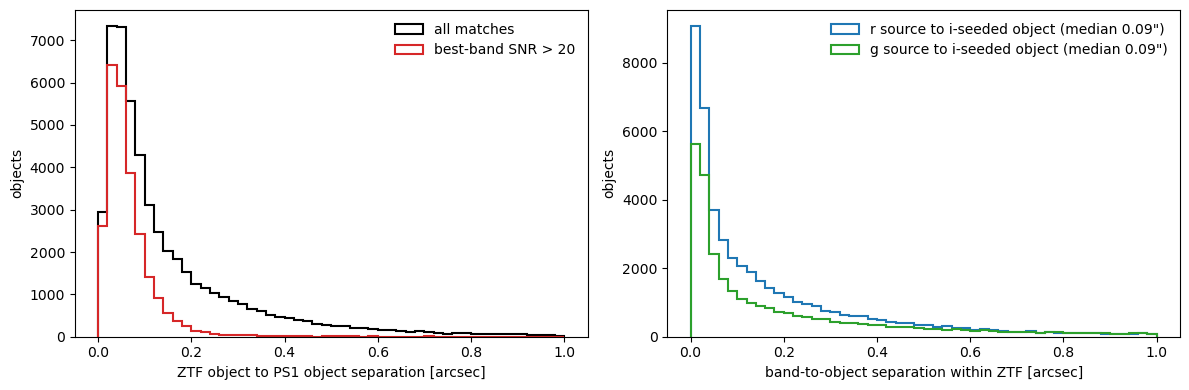

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(0, 1, 51)
axes[0].hist(matched.ps1_sep, bins=bins, histtype='step', lw=1.5, color='k', label='all matches')
bright = matched[matched[['g_snr', 'r_snr', 'i_snr']].max(axis=1) > 20]
axes[0].hist(bright.ps1_sep, bins=bins, histtype='step', lw=1.5, color='C3', label='best-band SNR > 20')
axes[0].set_xlabel('ZTF object to PS1 object separation [arcsec]')
axes[0].set_ylabel('objects')
axes[0].legend(frameon=False)
for b, c in zip('rg', ['C0', 'C2']):
    s = obj[f'{b}_sep'].dropna()
    axes[1].hist(s, bins=bins, histtype='step', lw=1.5, color=c, label=f'{b} source to i-seeded object (median {s.median():.2f}")')
axes[1].set_xlabel('band-to-object separation within ZTF [arcsec]')
axes[1].set_ylabel('objects')
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

## 2. PS1 PSF vs ZTF PSF magnitude per band

Point sources (|PS1 PSF − Kron| < 0.05) in black, everything else in colour. The dashed line is equality; the lower row is the residual.

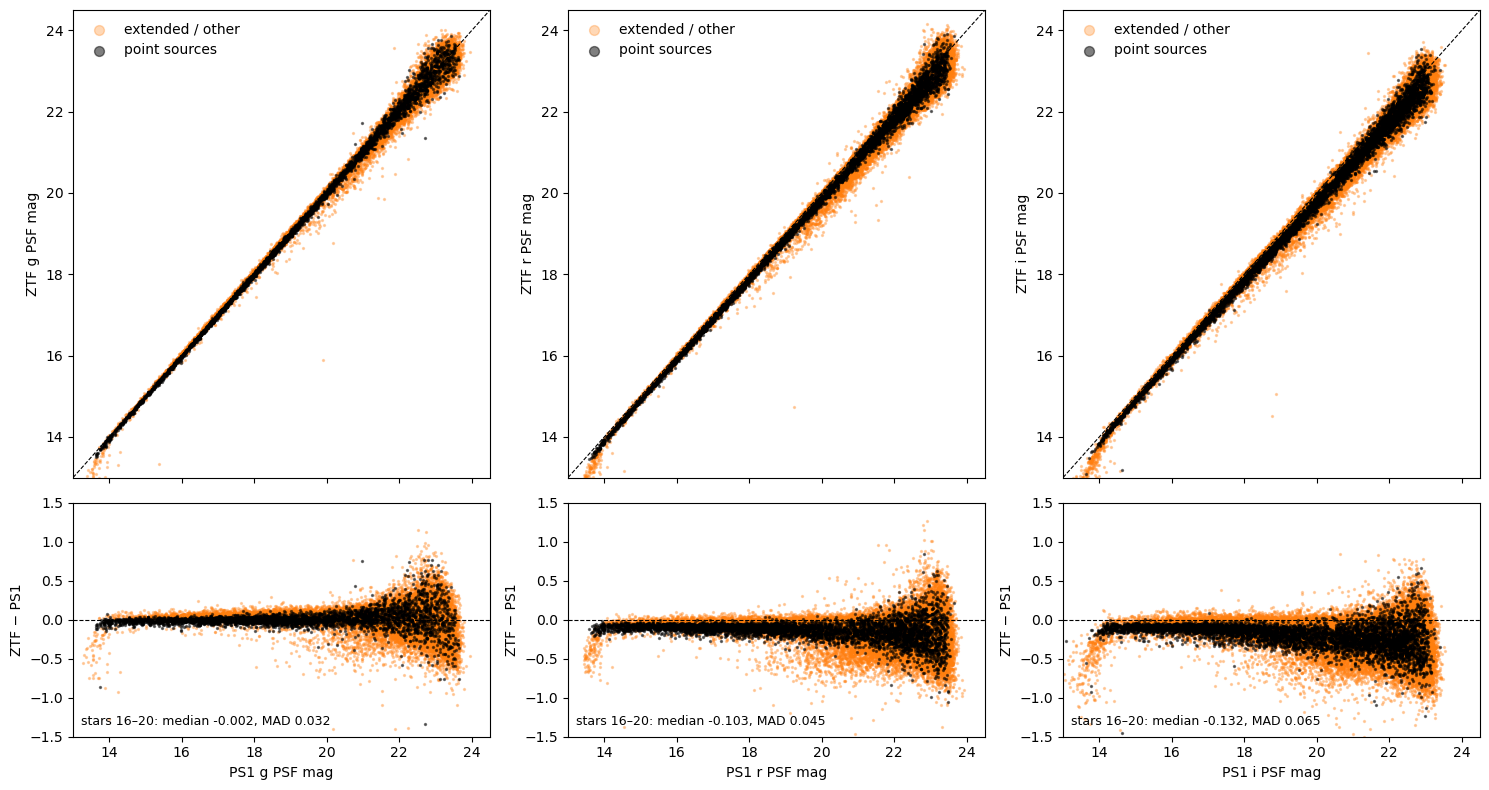

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex='col', gridspec_kw={'height_ratios': [2, 1]})
for j, b in enumerate('gri'):
    m = matched[matched[f'{b}_idx'] >= 0]
    x, y = m[f'ps1_{b}_psf'], m[f'{b}_mag']
    star = (m[f'ps1_{b}_psf'] - m[f'ps1_{b}_kron']).abs() < 0.05
    ax = axes[0, j]
    ax.scatter(x[~star], y[~star], s=2, alpha=0.3, color='C1', label='extended / other')
    ax.scatter(x[star], y[star], s=2, alpha=0.5, color='k', label='point sources')
    lim = (13, 24.5)
    ax.plot(lim, lim, 'k--', lw=0.8)
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_ylabel(f'ZTF {b} PSF mag')
    ax.legend(frameon=False, loc='upper left', markerscale=5)
    ax = axes[1, j]
    d = y - x
    ax.scatter(x[~star], d[~star], s=2, alpha=0.3, color='C1')
    ax.scatter(x[star], d[star], s=2, alpha=0.5, color='k')
    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.set_ylim(-1.5, 1.5)
    ax.set_xlabel(f'PS1 {b} PSF mag')
    ax.set_ylabel('ZTF − PS1')
    sel = star & (x > 16) & (x < 20)
    ax.text(0.02, 0.05, f'stars 16–20: median {d[sel].median():+.3f}, MAD {1.4826*np.median(np.abs(d[sel]-d[sel].median())):.3f}', transform=ax.transAxes, fontsize=9)
plt.tight_layout()
plt.show()

## 3. Unmatched examples

Rows are objects with no counterpart: first the brightest ZTF-only objects detected in at least two bands, then the brightest PS1-only objects. Left is the ZTF r reference, right the PS1 r stack (from the local skycells), both 30" on a side. Circles are ZTF DAOPhot detections (g green, r red, i purple), squares are PS1 objects. The cross marks the object in question.

In [ ]:
import glob, os, sys
sys.path.insert(0, '..')
from astropy.nddata import Cutout2D
from astropy.coordinates import SkyCoord
import astropy.units as u
from Extracting.images import load_ztf_refimg, load_ps1_skycell
from Extracting.ztf_images import refimg_path

D = '../Data'
ztf_img = load_ztf_refimg(refimg_path(f'{D}/ztf_data', 643, 11, 1, 'r'))
ztf_cat = {b: pd.read_parquet(f'{D}/ztf_data/ztfpsf_643_11_1_{b}.parquet') for b in 'gri'}
ps1_imgs = {}   # loaded on demand, keyed by skycell name
def ps1_image_at(ra, dec):
    for stack in sorted(glob.glob(f'{D}/ps1_data/rings.v3.skycell.*.stk.r.unconv.fits')):
        name = os.path.basename(stack).split('.stk.')[0]
        if name not in ps1_imgs:
            ps1_imgs[name] = load_ps1_skycell(stack, stack.replace('.fits', '.mask.fits'))
        im = ps1_imgs[name]
        x, y = im.wcs.world_to_pixel_values(ra, dec)
        if 70 < x < im.shape[1] - 70 and 70 < y < im.shape[0] - 70:
            return im
    return None

def show(ax, im, ra, dec, size_arcsec=30):
    cut = Cutout2D(im.data, SkyCoord(ra * u.deg, dec * u.deg), size_arcsec * u.arcsec, wcs=im.wcs)
    lo, hi = np.nanpercentile(cut.data, [5, 99.5])
    ax.imshow(np.arcsinh((cut.data - lo) / max(hi - lo, 1e-3) * 10), origin='lower', cmap='gray_r')
    for b, c in zip('gri', ['limegreen', 'red', 'purple']):
        cat = ztf_cat[b]
        x, y = cut.wcs.world_to_pixel_values(cat.ra.values, cat.dec.values)
        s = (x > 0) & (x < cut.shape[1]) & (y > 0) & (y < cut.shape[0])
        ax.scatter(x[s], y[s], s=60, facecolors='none', edgecolors=c, lw=1.2)
    x, y = cut.wcs.world_to_pixel_values(ps1.ra.values, ps1.dec.values)
    s = (x > 0) & (x < cut.shape[1]) & (y > 0) & (y < cut.shape[0])
    ax.scatter(x[s], y[s], s=90, marker='s', facecolors='none', edgecolors='dodgerblue', lw=1.2)
    x0, y0 = cut.wcs.world_to_pixel_values(ra, dec)
    ax.plot(x0, y0, '+', color='orange', ms=14, mew=1.5)
    ax.set_xticks([]); ax.set_yticks([])

ztf_only = obj[(obj.ps1_idx < 0) & (obj.nbands >= 2)].sort_values('best_snr', ascending=False).head(4)
ps1_only_mask = ~np.isin(np.arange(len(ps1)), obj.ps1_idx[obj.ps1_idx >= 0])
ps1_only = ps1[ps1_only_mask & (ps1.rPSFMag > 0)].sort_values('rPSFMag').head(4)
rows = [(r.ra, r.dec, f'ZTF-only  nbands={r.nbands}  best SNR={r.best_snr:.0f}  r={r.r_mag:.1f}') for r in ztf_only.itertuples()] +        [(r.ra, r.dec, f'PS1-only  r PSF={r.rPSFMag:.1f}  Kron={r.rKronMag:.1f}') for r in ps1_only.itertuples()]
fig, axes = plt.subplots(len(rows), 2, figsize=(8, 4 * len(rows)))
for (ra, dec, label), (axl, axr) in zip(rows, axes):
    show(axl, ztf_img, ra, dec)
    axl.set_ylabel(label, fontsize=9)
    pim = ps1_image_at(ra, dec)
    if pim is not None:
        show(axr, pim, ra, dec)
    else:
        axr.set_axis_off()
axes[0, 0].set_xlabel('ZTF r reference'); axes[0, 1].set_xlabel('PS1 r stack')
plt.tight_layout()
plt.show()